In [1]:
import numpy as np
import pandas as pd
from scipy.interpolate import BarycentricInterpolator
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

1. Floating point representation
For the float data type, write a program to empirically (i.e., by
performing tests on the results of addition and subtraction operations
within your program) determine the following “Machine constants” for
your computer:
(a) The smallest ϵ such that 1.0 − ϵ̸ = 1.0
(b) The smallest ϵ such that 1.0 + ϵ̸ = 1.0
(c) The maximum representable number
(d) The minimum representable positive number
Provide all the above answers to better than 10% accuracy, and
comment on why the numbers you get are expected based on the
IEEE 754 representation.

In [2]:
def find_smallest_eps_subtraction():
    eps = np.float32(1.0)
    smallest_eps = eps

    # keep dividing by a value until python rounds 
    while np.float32(1.0) - eps != np.float32(1.0):
        smallest_eps = eps
        eps = np.float32(eps) / np.float32(2)

    return smallest_eps


smallest_eps = find_smallest_eps_subtraction()
print(f"The smallest float epsilon (subtraction) is {smallest_eps}")

The smallest float epsilon (subtraction) is 5.960464477539063e-08


One is represented by 2^0, so when we are under 1, we represent it by 2^-1, since I'm working in single prescision there is 23 bits of mantesa. Since there are 23 bits avalible and we are representing a number below 1, our epsilon should be 2^-24. which 5.9e-08 is approximently equal to.

In [3]:
def find_smallest_eps_addition():

    eps = np.float32(1.0)
    smallest_eps = eps
    
    # same thought process as the above lines, just addition instead of subtraction
    while np.float32(1.0) + eps != np.float32(1.0):
        smallest_eps = eps
        eps = np.float32(eps) / np.float32(2)

    return smallest_eps

smallest_eps = find_smallest_eps_addition()
print(f"The smallest float epsilon (addition) is {smallest_eps}")

The smallest float epsilon (addition) is 1.1920928955078125e-07


Since we are now representing something approximentaly 1, we can represent the number as 2^0. Since it's still in single precsision, our mantesa still has 23 bits avalible (represented as 2^-23) our epsilon should be 2^-23 which is approximentaly equal to ~1.19e-7.

In [4]:
def find_max_float():
    #Find the largest power of 2 before overflowing
    val = np.float32(1.0)
    while val * np.float32(2.0) != float('inf'):
        val *= np.float32(2.0)

    # fill in the rest of the values
    max_float = val
    increment = val / np.float32(2.0)

    # check to see if an intger of 2 will overflow
    while increment > 0:
        if (max_float + increment) != float('inf'):
            max_float += increment
        increment /= np.float32(2.0)
        
    return max_float

max_float = find_max_float()

print(f"The largest float that can be represented is {max_float}")
print(f"This value is very similar to the value recorded in IEEE 754 MAXVAL when rounded")

The largest float that can be represented is 3.4028234663852886e+38
This value is very similar to the value recorded in IEEE 754 MAXVAL when rounded


/tmp/ipykernel_2463/2475852374.py:4: RuntimeWarning: overflow encountered in scalar multiply
  while val * np.float32(2.0) != float('inf'):
/tmp/ipykernel_2463/2475852374.py:13: RuntimeWarning: overflow encountered in scalar add
  if (max_float + increment) != float('inf'):


This makes sense because positive numbers are represented in bits 2^0 to 2^127, therefore the largest possible representable float would be 2^127, which is approximentaly equal to 3.4e+38.

In [5]:
def find_min_float():
    #Find the largest power of 2 before overflowing
    val = np.float32(1.0)
    while val / np.float32(2.0) > 0.0:
        val /= np.float32(2.0)

    #fill in the rest of the values
    min_float = val
    increment = val / np.float32(2.0)
        
    return min_float

min_float = find_min_float()

print(f"The largest float that can be represented is {min_float}")

The largest float that can be represented is 1.401298464324817e-45


Since machines are able to support subnormal numbers, the possible bits avalible are more than they used to be. This means that when you take the minimal possible exponenet of 2^-126 (1 - 127 instead of the 254-127 for largest possible value) and then multiply it by 2^-23 (found previously since we've shifted down to zero) we get 2^-149 which is approximentaly equal to 1.4e-45.

2. Floating point representation and rounding
Write a method to sum the elements of an array using using only
numpy.float32 operations (32 bit IEEE 754 floating point). For this
part of the problem, avoid using the numpy internal sum method (see
below). Generate an array of 20 million random numbers of type
float32 (32 bit IEEE 754 floating point) between 0 and 1 (use an
available method such as numpy.random.rand() in Python), and use
your method to calculate the the sum of the numbers in the array
(a) in the order as produced by rand(),
(b) after being sorted from smallest to largest
(c) after being sorted from largest to smallest.
Explain the differences in the results from your sum method based on
the limitations of the IEEE 754 precision. Also calculate the above
sums using the internal numpy.ndarray.sum() method. Speculate on
how the internal method differs from your implementation.

In [6]:
#set the length of the array and generate the values
n = 20000000
random_array = np.random.rand(n).astype(np.float32)

In [7]:
def array_sum(a):
    s = 0
    for i in a:
        s += i
    return s

In [8]:
#sort for part b
sorted_b = np.sort(random_array)

#sort for part c
sorted_c = sorted_b[::-1]

In [9]:
#the sums for part a
numpy_sum_random = random_array.sum()
personal_sum_random = array_sum(random_array)

print(f"{numpy_sum_random} and {personal_sum_random}")

10000743.0 and 10002094.0


This is the best way to calculate the numbers as there is a more consistent difference in number values which means no major rounding issues are going to occur throughout the addition of the random array like when you sort it.

In [10]:
#sums for part b
numpy_sum_b = sorted_b.sum()
personal_sum_b = array_sum(sorted_b)

print(f"{numpy_sum_b} and {personal_sum_b}")

10000743.0 and 10168606.0


Since we start with the small numbers first, they are able to be added together and get to a suitable size without any rounding errors, but once we reach the larger values, the errors start accumulating and lead to a large overshoot.

In [11]:
#sums for part c
numpy_sum_c = sorted_c.sum()
personal_sum_c = array_sum(sorted_c)

print(f"{numpy_sum_c} and {personal_sum_c}")

10000743.0 and 8388608.0


For part C, when you get to the very end of the array, the values being sorted are super small, but the next integer that can be represented is 1.0 larger than 8388608 and much smaller than 0.5, which means that all the values after 8388608 are being rounded down and not adding up to reach the final value.

3. Roundoff error
Numerically evaluate the expression (1−cos(x))/x2 in double precision
for values of x around 10e−7 and smaller. Explain the difference between
the numerical results and the analytic limit as x → 0.
Explain why trouble is occurring at x ∼ 10e−7 when double precision is
good to ∼ 10e−15?

In [12]:
def expression(x):
    
    y = (1.0 - np.cos(np.float64(x))) / x**2

    return y

In [13]:
x_values = [1e-7, 1e-8, 1e-9, 1e-10]
y_values = []

for i in x_values:
    y_values = expression(i)
    print(y_values)

0.4996003610813205
0.0
0.0
0.0


We have this issue because when the machine is evaluating cos(x), it taylor expands it resulting in an approximation of 1- x^2/2. Therefore, the machine prescision scales with x^2 rather than with x, meaning that as we hit 1e-8, we're really hitting the prescision of 1e-16 which is where the machine looses precision.

4. Interpolation
(a) Write a program to read in a two column table from a file and per-
form linear interpolation at an arbitrary point. You may assume
that the data is evenly spaced in the independent variable (this
makes it easier to determine which points to use for interpolation).
(b) Use the program on the following input data: (available on the
canvas site as hw_data.csv)
x y
1 100
2 25
3 11.111111
4 6.25
5 4
and provide an estimate of y at x = 4.75.
(c) Either using your own routine or a package (e.g. scipy.interpolate)
calculate interpolated values of y at 100 equally spaced points be-
tween x = 1 and x = 5 using the above data with linear, quadratic,
and 4th order polynomials, and plot the interpolated y vs. x.
(Note: we are NOT performing a “fit” here; we want polynomi-
als that go exactly through all the given data points.) Give an
estimate of y at x = 4.75 for each of these polynomial orders.
(d) The actual function tabulated above is y = 100
x2 . Compare the
actual value at x = 4.75 with the linear interpolation and the 4th
order polynomial interpolation, and comment on why one is more
accurate than the other.

In [14]:
# function created for linear interpolation

def linear_interpolation(data, x_value):

    # reading in the csv data file and getting the x and y columns
    data = pd.read_csv(data)
    x_data = data.iloc[:, 0]
    y_data = data.iloc[:, 1]

    # check to make sure that the inputed x value is actually in our data range
    if x_value < x_data.iloc[0] or x_value > x_data.iloc[-1]:
        raise ValueError("Target x value is outside of the range of the data given")

    # calculates difference between different spaces
    dx = x_data.iloc[1] - x_data.iloc[0]

    # finds where the x value lives
    idx = int((x_value - x_data.iloc[0]) / dx)

    # keeps any values from being 'out of bounds'
    if idx >= len(x_data) - 1:
        idx = len(x_data) - 2

    # specify the binding points
    x0, x1 = x_data.iloc[idx], x_data.iloc[idx + 1]
    y0, y1 = y_data.iloc[idx], y_data.iloc[idx + 1]

    # actually preform the linear interpolation caluclation
    y_target = y0 + (x_value - x0) * (y1 - y0) / (x1 - x0)

    return y_target

In [15]:
# call the function to find the estimation with x = 4.75
estimation = linear_interpolation("hw1_data.csv", 4.75)

print(f"The estimation of the y value of x = 4.75 is {estimation}")

The estimation of the y value of x = 4.75 is 4.5625


In [16]:
# define the x and y data from the .csv file
data = pd.read_csv("hw1_data.csv")
x_data = data.iloc[:, 0]
y_data = data.iloc[:, 1]

# create the 100 equally spaced points between 1 and 5
x_linespace = np.linspace(1, 5, 100)

# calculate the y values using different interpolation strategies
y_linear = interp1d(x_data, y_data, kind='linear')(x_linespace)
y_quadratic = interp1d(x_data, y_data, 'quadratic')(x_linespace)
y_poly = BarycentricInterpolator(x_data, y_data)(x_linespace)

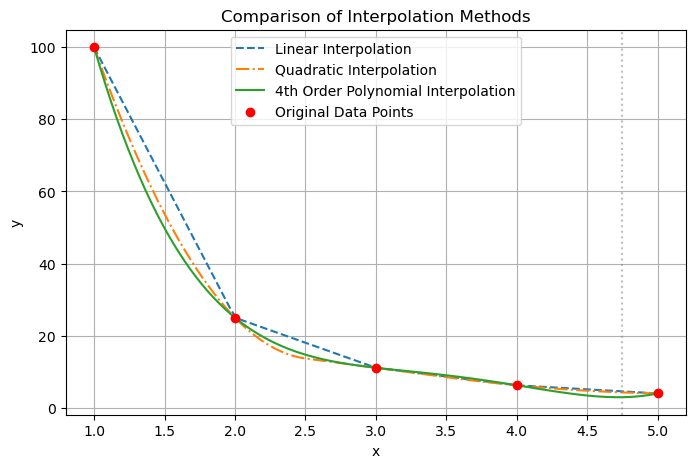

In [17]:
# plot the interpolation graphs on one set of axis

plt.figure(figsize=(8, 5))
plt.plot(x_linespace, y_linear, label='Linear Interpolation', linestyle='--')
plt.plot(x_linespace, y_quadratic, label='Quadratic Interpolation', linestyle='-.')
plt.plot(x_linespace, y_poly, label='4th Order Polynomial Interpolation', linestyle='-')
plt.scatter(x_data, y_data, color='red', zorder=5, label='Original Data Points')
plt.axvline(4.75, color='gray', alpha=0.5, linestyle=':')
plt.title('Comparison of Interpolation Methods')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# set x value
x = 4.75

# find y values without factoring in the linespace for graphing
y_linear = interp1d(x_data, y_data, kind='linear')
y_quadratic = interp1d(x_data, y_data, 'quadratic')
y_poly = BarycentricInterpolator(x_data, y_data)

# calculation the estimations
linear_estimation = y_linear(x)
quadratic_estimation = y_quadratic(x)
poly_estimation = y_poly(x)

In [19]:
print(f"The linear estimation of 4.75 is {linear_estimation}")
print(f"The quadratic estimation of 4.75 is {quadratic_estimation}")
print(f"The poly estimation of 4.75 is {poly_estimation}")

The linear estimation of 4.75 is 4.5625
The quadratic estimation of 4.75 is 4.281324421428571
The poly estimation of 4.75 is 2.951660209960938


The actual value of y at 4.75 in the equation given is approx. 4.4321. Between this real value and the value calculated using the 4th order polynomial, there's an approximently 33% error. The linear estimation is so much more accurate because doesn't try to assume future behavoir about the function like the 4th order polynomial does. As we can see in the graph, there are strange swings that happen in-between points that affect the approximation of values that isn't present in the linear interpolation.